# Load Data

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pygam import LinearGAM
from pygam.terms import s, te
from scipy.interpolate import BSpline
from scipy.stats import t, ttest_1samp
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from tqdm.auto import tqdm

''' ---------------------------------------------------------------------------
    File description
'''

data = np.load(Path("..") / "data" / "mechanical_fingerprint.npz")

params = ["A", "B", "alpha", "beta", "E", "gamma"]
dirs = ["x", "y"]

log_params = {"A", "B", "E"}

dfs = {}

symmetry_x = 162.5

''' ---------------------------------------------------------------------------
    Symmetry and applying logarithm
'''

for d in dirs:
    coords_key = "coords_x_trans_ds_2" if d == "x" else "coords_y_trans_ds_2"
    coords = data[coords_key]

    df_d = pd.DataFrame({
        "cell_idx": data["cell_idx"],
        "cell_label": data["cell_label_in_day_folder"],
        "x_pos": coords[:, 0] - symmetry_x,
        "y_pos": coords[:, 1],
    })

    for p in params:
        values = data[f"{p}_{d}"]

        if p in log_params:
            df_d[f"log{p}"] = np.log(values)
        else:
            df_d[p] = values

    dfs[d] = df_d

''' ---------------------------------------------------------------------------
    Cleanup
'''

df_x = dfs["x"].replace([np.inf, -np.inf], np.nan).dropna()
df_y = dfs["y"].replace([np.inf, -np.inf], np.nan).dropna()

''' ---------------------------------------------------------------------------
    Cell Boundary Shape
'''

border_data = np.load(Path("..") / "data" / "actin_nucleus_borders.npz")
border_x = border_data['actin_border_x'] - symmetry_x
border_y = border_data['actin_border_y']

# Select Channel

C1 loadings (logA, logB, alpha, beta, logE, gamma): [-0.3518 -0.5364  0.5077  0.5387 -0.1965  0.0437]
C1 explained variance: 0.4732179339475875


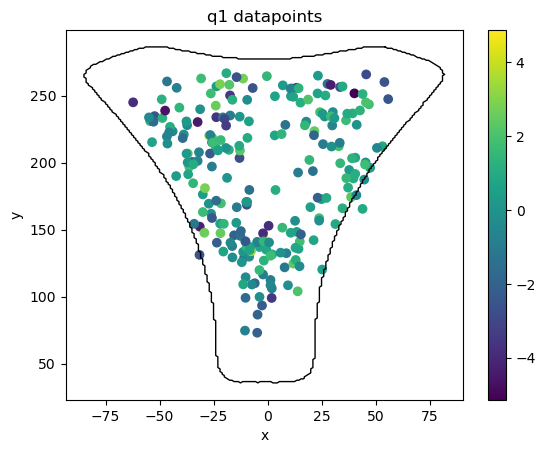

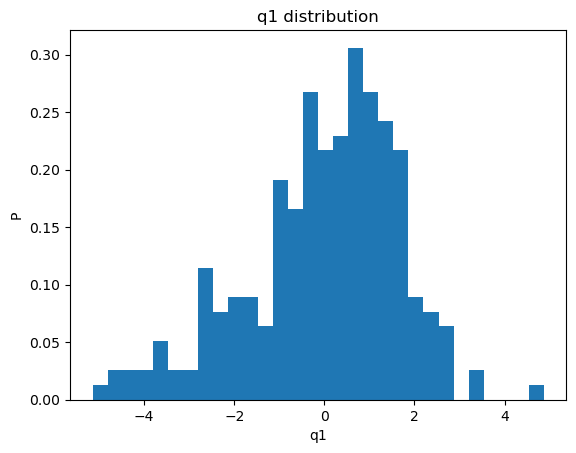

In [2]:
F_name = 'q1' # 'q1', 'z(log(A))', or 'z(log(E))'
df = df_y     # df_x or df_y


''' Python names for easy access '''

x = df.x_pos.to_numpy()
y = df.y_pos.to_numpy()

logA = df.logA.to_numpy()
logB = df.logB.to_numpy()
alpha = df.alpha.to_numpy()
beta = df.beta.to_numpy()
logE = df.logE.to_numpy()
gamma = df.gamma.to_numpy()

''' z normalized fields '''

logA = (logA - logA.mean()) / logA.std()
logB = (logB - logB.mean()) / logB.std()
alpha = (alpha - alpha.mean()) / alpha.std()
beta = (beta - beta.mean()) / beta.std()
logE = (logE - logE.mean()) / logE.std()
gamma = (gamma - gamma.mean()) / gamma.std()

''' First principal component (fluidity) '''

Z = np.column_stack([logA, logB, alpha, beta, logE, gamma])

eigval, eigvec = np.linalg.eigh(np.cov(Z, rowvar=False))
v1 = eigvec[:, np.argmax(eigval)]

if v1[3] < 0:   # orient so that larger C1 = more fluid-like (beta loading positive)
    v1 = -v1

print("C1 loadings (logA, logB, alpha, beta, logE, gamma):", np.round(v1, 4))
print("C1 explained variance:", eigval.max() / eigval.sum())

q1 = Z @ v1

''' Fied selection '''

FIELDS = {'q1': q1, 'z(log(A))': logA, 'z(log(E))': logE}
F = FIELDS[F_name]

''' Basic plotting '''

plt.scatter(x, y, c=F)
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"{F_name} datapoints")
plt.colorbar()
plt.plot(border_x, border_y, '-k', lw=1)
plt.show()

plt.hist(F, bins=30, density=True)
plt.xlabel(F_name)
plt.ylabel("P")
plt.title(f"{F_name} distribution")
plt.show()

# Simple Cross Validation GAM tuning

In [3]:
n_splines = 15
n_folds = 30

lambda_grid = np.logspace(-5, 3, 30)

X = np.column_stack([x, y])

x_domain = np.concatenate([
    x,
    -x,
    border_x,
    -border_x,
])

y_domain = np.concatenate([
    y,
    border_y,
])

x_min = np.min(x_domain)
x_max = np.max(x_domain)
y_min = np.min(y_domain)
y_max = np.max(y_domain)

x_pad = 0.02 * (x_max - x_min)
y_pad = 0.02 * (y_max - y_min)

edge_knots = [
    [x_min - x_pad, x_max + x_pad],
    [y_min - y_pad, y_max + y_pad],
]

kf = KFold(
    n_splits=n_folds,
    shuffle=True,
    random_state=42,
)

splits = list(kf.split(X))

constant_fold_mse = []

for train_idx, val_idx in splits:
    F_constant = np.full(
        len(val_idx),
        np.mean(F[train_idx]),
    )

    constant_fold_mse.append(
        mean_squared_error(
            F[val_idx],
            F_constant,
        )
    )

constant_cv_mse = np.mean(constant_fold_mse)
constant_cv_std = np.std(constant_fold_mse)

mean_mse = []
std_mse = []

for lam in tqdm(lambda_grid, desc="Lambda grid search"):
    fold_mse = []

    for train_idx, val_idx in splits:
        x_train = x[train_idx]
        y_train = y[train_idx]
        F_train = F[train_idx]

        x_train_sym = np.concatenate([
            x_train,
            -x_train,
        ])

        y_train_sym = np.concatenate([
            y_train,
            y_train,
        ])

        F_train_sym = np.concatenate([
            F_train,
            F_train,
        ])

        X_train_sym = np.column_stack([
            x_train_sym,
            y_train_sym,
        ])

        X_val = np.column_stack([
            x[val_idx],
            y[val_idx],
        ])

        gam_cv = LinearGAM(
            te(
                0,
                1,
                n_splines=[n_splines, n_splines],
                lam=[lam, lam],
                edge_knots=edge_knots,
            )
        ).fit(
            X_train_sym,
            F_train_sym,
        )

        F_val_pred = gam_cv.predict(X_val)

        fold_mse.append(
            mean_squared_error(
                F[val_idx],
                F_val_pred,
            )
        )

    mean_mse.append(np.mean(fold_mse))
    std_mse.append(np.std(fold_mse))

mean_mse = np.array(mean_mse)
std_mse = np.array(std_mse)

best_idx = np.argmin(mean_mse)
worst_idx = np.argmax(mean_mse)

best_lam = lambda_grid[best_idx]
worst_lam = lambda_grid[worst_idx]

print("best lambda:", best_lam)
print("best CV MSE:", mean_mse[best_idx])
print("best CV RMSE:", np.sqrt(mean_mse[best_idx]))

print("worst lambda:", worst_lam)
print("worst CV MSE:", mean_mse[worst_idx])
print("worst CV RMSE:", np.sqrt(mean_mse[worst_idx]))

print("constant CV MSE:", constant_cv_mse)
print("constant CV RMSE:", np.sqrt(constant_cv_mse))

x_sym = np.concatenate([
    x,
    -x,
])

y_sym = np.concatenate([
    y,
    y,
])

F_sym = np.concatenate([
    F,
    F,
])

X_sym = np.column_stack([
    x_sym,
    y_sym,
])

gam_best = LinearGAM(
    te(
        0,
        1,
        n_splines=[n_splines, n_splines],
        lam=[best_lam, best_lam],
        edge_knots=edge_knots,
    )
).fit(
    X_sym,
    F_sym,
)

gam_worst = LinearGAM(
    te(
        0,
        1,
        n_splines=[n_splines, n_splines],
        lam=[worst_lam, worst_lam],
        edge_knots=edge_knots,
    )
).fit(
    X_sym,
    F_sym,
)

X_data = np.column_stack([
    x,
    y,
])

F_fit_best = gam_best.predict(X_data)
F_fit_worst = gam_worst.predict(X_data)

constant_value = np.mean(F)
F_fit_constant = np.full_like(
    F,
    constant_value,
    dtype=float,
)

print("best effective DoF:", gam_best.statistics_["edof"])
print("best correlation:", np.corrcoef(F, F_fit_best)[0, 1])
print("best prediction std:", np.std(F_fit_best))

print("worst effective DoF:", gam_worst.statistics_["edof"])
print("worst correlation:", np.corrcoef(F, F_fit_worst)[0, 1])
print("worst prediction std:", np.std(F_fit_worst))

print("experimental std:", np.std(F))
print("constant prediction:", constant_value)

Lambda grid search:   0%|          | 0/30 [00:00<?, ?it/s]

best lambda: 1.7433288221999872
best CV MSE: 2.7932904716696156
best CV RMSE: 1.6713139955345362
worst lambda: 1e-05
worst CV MSE: 3.7298130456688012
worst CV RMSE: 1.9312723903346212
constant CV MSE: 2.8763912785916923
constant CV RMSE: 1.6959927118333062
best effective DoF: 14.28396642926222
best correlation: 0.3072985435150323
best prediction std: 0.3773030232979808
worst effective DoF: 89.36939415619364
worst correlation: 0.4973104435904287
worst prediction std: 0.8150751564367091
experimental std: 1.685024511301105
constant prediction: 3.628303331540937e-16


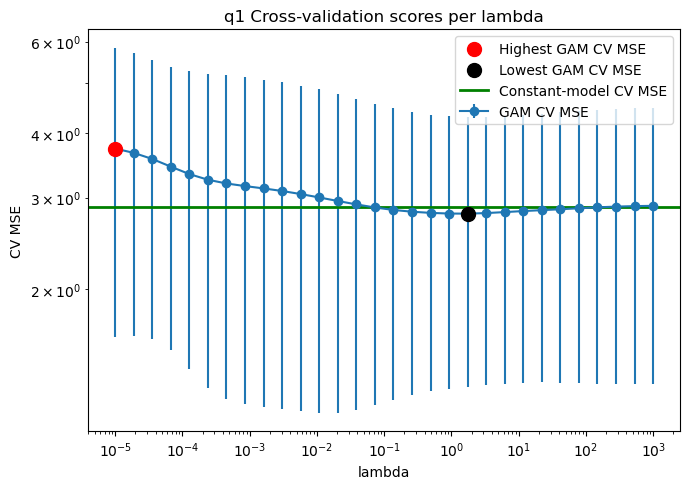

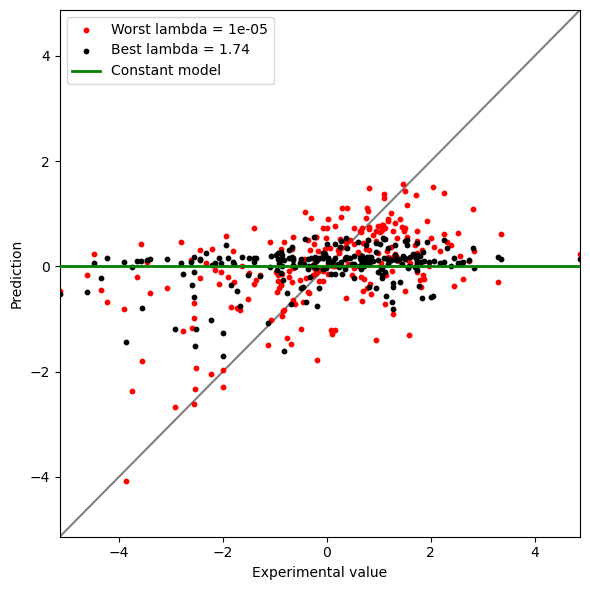

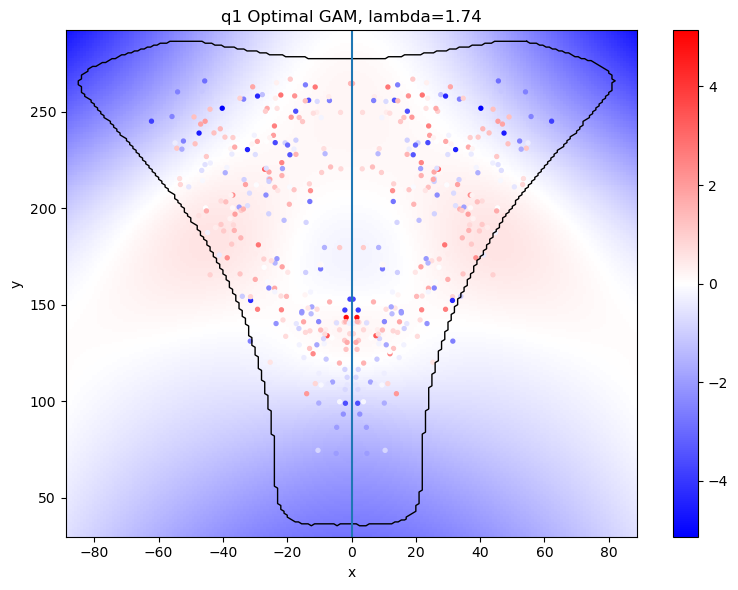

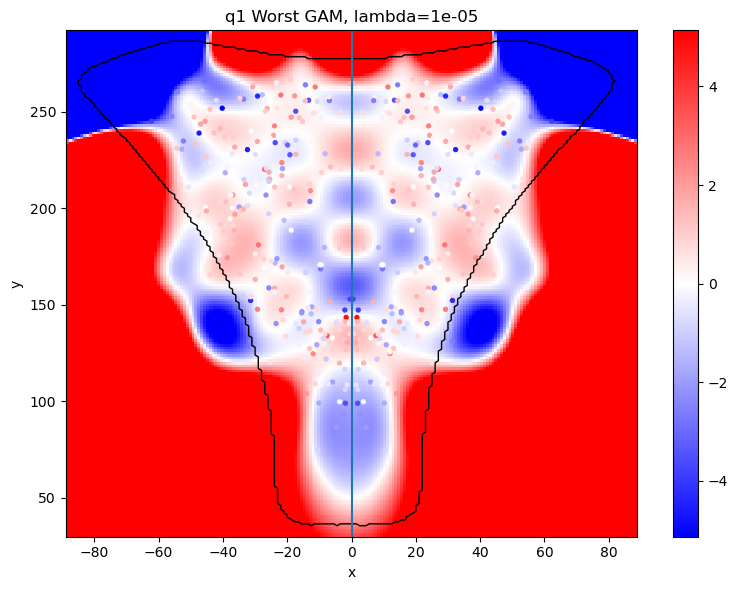

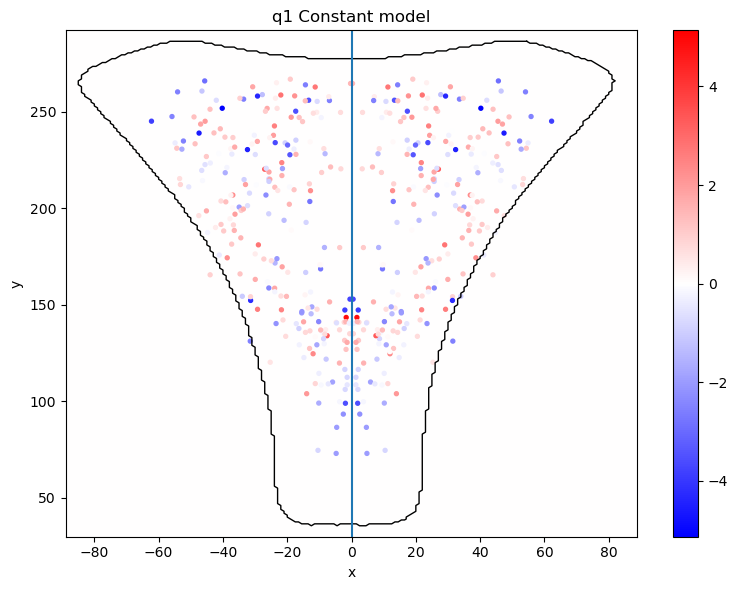

In [4]:
lims = [
    min(
        F.min(),
        F_fit_best.min(),
        F_fit_worst.min(),
        F_fit_constant.min(),
    ),
    max(
        F.max(),
        F_fit_best.max(),
        F_fit_worst.max(),
        F_fit_constant.max(),
    ),
]

nx = 200
ny = 200

x_grid = np.linspace(
    edge_knots[0][0],
    edge_knots[0][1],
    nx,
)

y_grid = np.linspace(
    edge_knots[1][0],
    edge_knots[1][1],
    ny,
)

xx, yy = np.meshgrid(
    x_grid,
    y_grid,
)

X_grid = np.column_stack([
    xx.ravel(),
    yy.ravel(),
])

F_grid_best = gam_best.predict(X_grid).reshape(ny, nx)
F_grid_worst = gam_worst.predict(X_grid).reshape(ny, nx)
F_grid_constant = np.full(
    (ny, nx),
    constant_value,
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.errorbar(
    lambda_grid,
    mean_mse,
    yerr=std_mse,
    marker="o",
    label="GAM CV MSE",
)

ax.scatter(
    worst_lam,
    mean_mse[worst_idx],
    s=100,
    color="red",
    zorder=10,
    label="Highest GAM CV MSE",
)

ax.scatter(
    best_lam,
    mean_mse[best_idx],
    s=100,
    color="black",
    zorder=11,
    label="Lowest GAM CV MSE",
)

ax.axhline(
    constant_cv_mse,
    color="green",
    linewidth=2,
    label="Constant-model CV MSE",
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("lambda")
ax.set_ylabel("CV MSE")
ax.set_title(f"{F_name} Cross-validation scores per lambda")
ax.legend()

fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    F,
    F_fit_worst,
    s=10,
    color="red",
    label=f"Worst lambda = {worst_lam:.3g}",
    zorder=1,
)

ax.scatter(
    F,
    F_fit_best,
    s=10,
    color="black",
    label=f"Best lambda = {best_lam:.3g}",
    zorder=2,
)

ax.axhline(
    constant_value,
    color="green",
    linewidth=2,
    label="Constant model",
    zorder=3,
)

ax.plot(
    lims,
    lims,
    "-",
    color="grey",
    zorder=0,
)

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Experimental value")
ax.set_ylabel("Prediction")
ax.legend()

fig.tight_layout()
plt.show()

vmax = np.max(np.abs(F_sym))
vmin = -vmax

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.pcolormesh(
    xx,
    yy,
    F_grid_best,
    shading="auto",
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.scatter(
    x_sym,
    y_sym,
    s=8,
    c=F_sym,
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.plot(
    border_x,
    border_y,
    "-k",
    lw=1,
)


ax.axvline(0)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{F_name} Optimal GAM, lambda={best_lam:.3g}")

fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.pcolormesh(
    xx,
    yy,
    F_grid_worst,
    shading="auto",
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.scatter(
    x_sym,
    y_sym,
    s=8,
    c=F_sym,
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.plot(
    border_x,
    border_y,
    "-k",
    lw=1,
)


ax.axvline(0)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{F_name} Worst GAM, lambda={worst_lam:.3g}")

fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.pcolormesh(
    xx,
    yy,
    F_grid_constant,
    shading="auto",
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.scatter(
    x_sym,
    y_sym,
    s=8,
    c=F_sym,
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.plot(
    border_x,
    border_y,
    "-k",
    lw=1,
)

ax.axvline(0)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{F_name} Constant model")

fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

# Nested Cross Validation

In [5]:
n_splines = 15
n_outer_folds = 15
n_inner_folds = 30

lambda_grid = np.logspace(-5, 3, 25)

X = np.column_stack([x, y])

x_domain = np.concatenate([
    x,
    -x,
    border_x,
    -border_x,
])

y_domain = np.concatenate([
    y,
    border_y,
])

x_min = np.min(x_domain)
x_max = np.max(x_domain)
y_min = np.min(y_domain)
y_max = np.max(y_domain)

x_pad = 0.02 * (x_max - x_min)
y_pad = 0.02 * (y_max - y_min)

edge_knots = [
    [x_min - x_pad, x_max + x_pad],
    [y_min - y_pad, y_max + y_pad],
]

outer_kf = KFold(
    n_splits=n_outer_folds,
    shuffle=True,
    random_state=42,
)

outer_gam_mse = []
outer_constant_mse = []
outer_delta = []
selected_lambdas = []

F_pred_gam_oof = np.full(len(F), np.nan)
F_pred_constant_oof = np.full(len(F), np.nan)

outer_splits = list(outer_kf.split(X))

for outer_fold, (train_idx, test_idx) in enumerate(
    tqdm(outer_splits, desc="Outer CV")
):
    x_train_outer = x[train_idx]
    y_train_outer = y[train_idx]
    F_train_outer = F[train_idx]

    x_test = x[test_idx]
    y_test = y[test_idx]
    F_test = F[test_idx]

    X_train_outer = np.column_stack([
        x_train_outer,
        y_train_outer,
    ])

    X_test = np.column_stack([
        x_test,
        y_test,
    ])

    inner_kf = KFold(
        n_splits=n_inner_folds,
        shuffle=True,
        random_state=1000 + outer_fold,
    )

    inner_lambda_mse = []

    for lam in lambda_grid:
        inner_fold_mse = []

        for inner_train_idx, inner_val_idx in inner_kf.split(X_train_outer):
            x_train = x_train_outer[inner_train_idx]
            y_train = y_train_outer[inner_train_idx]
            F_train = F_train_outer[inner_train_idx]

            x_val = x_train_outer[inner_val_idx]
            y_val = y_train_outer[inner_val_idx]
            F_val = F_train_outer[inner_val_idx]

            x_train_sym = np.concatenate([
                x_train,
                -x_train,
            ])

            y_train_sym = np.concatenate([
                y_train,
                y_train,
            ])

            F_train_sym = np.concatenate([
                F_train,
                F_train,
            ])

            X_train_sym = np.column_stack([
                x_train_sym,
                y_train_sym,
            ])

            X_val = np.column_stack([
                x_val,
                y_val,
            ])

            gam_inner = LinearGAM(
                te(
                    0,
                    1,
                    n_splines=[n_splines, n_splines],
                    lam=[lam, lam],
                    edge_knots=edge_knots,
                )
            ).fit(
                X_train_sym,
                F_train_sym,
            )

            F_val_pred = gam_inner.predict(X_val)

            inner_fold_mse.append(
                mean_squared_error(
                    F_val,
                    F_val_pred,
                )
            )

        inner_lambda_mse.append(
            np.mean(inner_fold_mse)
        )

    inner_lambda_mse = np.array(inner_lambda_mse)

    best_inner_idx = np.argmin(inner_lambda_mse)
    best_lam = lambda_grid[best_inner_idx]

    selected_lambdas.append(best_lam)

    x_train_sym = np.concatenate([
        x_train_outer,
        -x_train_outer,
    ])

    y_train_sym = np.concatenate([
        y_train_outer,
        y_train_outer,
    ])

    F_train_sym = np.concatenate([
        F_train_outer,
        F_train_outer,
    ])

    X_train_sym = np.column_stack([
        x_train_sym,
        y_train_sym,
    ])

    gam_outer = LinearGAM(
        te(
            0,
            1,
            n_splines=[n_splines, n_splines],
            lam=[best_lam, best_lam],
            edge_knots=edge_knots,
        )
    ).fit(
        X_train_sym,
        F_train_sym,
    )

    F_test_pred_gam = gam_outer.predict(X_test)

    constant_value = np.mean(F_train_outer)

    F_test_pred_constant = np.full(
        len(test_idx),
        constant_value,
    )

    gam_mse = mean_squared_error(
        F_test,
        F_test_pred_gam,
    )

    constant_mse = mean_squared_error(
        F_test,
        F_test_pred_constant,
    )

    delta = constant_mse - gam_mse

    outer_gam_mse.append(gam_mse)
    outer_constant_mse.append(constant_mse)
    outer_delta.append(delta)

    F_pred_gam_oof[test_idx] = F_test_pred_gam
    F_pred_constant_oof[test_idx] = F_test_pred_constant

outer_gam_mse = np.array(outer_gam_mse)
outer_constant_mse = np.array(outer_constant_mse)
outer_delta = np.array(outer_delta)
selected_lambdas = np.array(selected_lambdas)

mean_gam_mse = np.mean(outer_gam_mse)
mean_constant_mse = np.mean(outer_constant_mse)

mean_delta = np.mean(outer_delta)
std_delta = np.std(outer_delta, ddof=1)
sem_delta = std_delta / np.sqrt(n_outer_folds)

tcrit = t.ppf(
    0.975,
    df=n_outer_folds - 1,
)

ci_low = mean_delta - tcrit * sem_delta
ci_high = mean_delta + tcrit * sem_delta

relative_improvement = mean_delta / mean_constant_mse

fold_number = np.arange(1, n_outer_folds + 1)

lims = [
    min(
        F.min(),
        F_pred_gam_oof.min(),
        F_pred_constant_oof.min(),
    ),
    max(
        F.max(),
        F_pred_gam_oof.max(),
        F_pred_constant_oof.max(),
    ),
]

print("Nested CV GAM MSE:", mean_gam_mse)
print("Nested CV constant MSE:", mean_constant_mse)
print()
print("Mean delta:", mean_delta)
print("Delta std:", std_delta)
print("Delta SEM:", sem_delta)
print("95% CI for delta:", (ci_low, ci_high))
print()
print("Relative MSE improvement:", relative_improvement)
print()
print("Selected lambdas:", selected_lambdas)
print("Median selected lambda:", np.median(selected_lambdas))

Outer CV:   0%|          | 0/15 [00:00<?, ?it/s]

Nested CV GAM MSE: 2.8204913702636953
Nested CV constant MSE: 2.8726193681871455

Mean delta: 0.05212799792345078
Delta std: 0.3025328913363405
Delta SEM: 0.07811365665504165
95% CI for delta: (np.float64(-0.11540913301486451), np.float64(0.2196651288617661))

Relative MSE improvement: 0.018146503675614968

Selected lambdas: [2.15443469 2.15443469 2.15443469 2.15443469 2.15443469 0.1
 1.         1.         2.15443469 0.46415888 2.15443469 2.15443469
 2.15443469 2.15443469 2.15443469]
Median selected lambda: 2.154434690031882


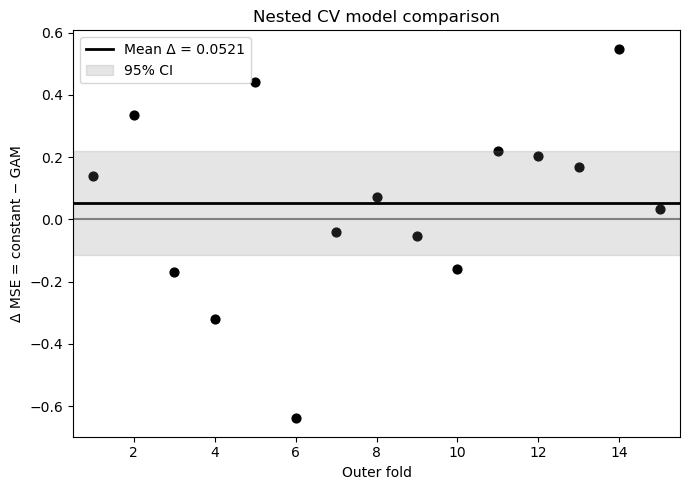

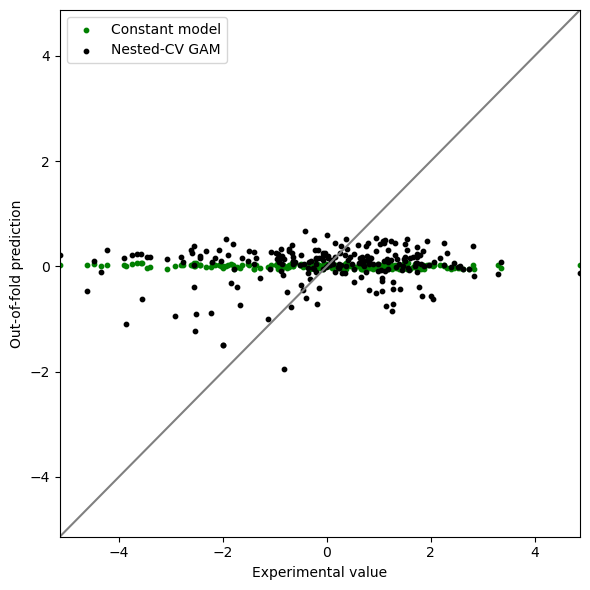

In [6]:
''' Plotting '''

fig, ax = plt.subplots(figsize=(7, 5))

ax.axhline(
    0,
    color="grey",
    linestyle="-",
)

ax.scatter(
    fold_number,
    outer_delta,
    s=40,
    color="black",
)

ax.axhline(
    mean_delta,
    color="black",
    linewidth=2,
    label=f"Mean Δ = {mean_delta:.3g}",
)

ax.fill_between(
    [0.5, n_outer_folds + 0.5],
    ci_low,
    ci_high,
    color="grey",
    alpha=0.2,
    label="95% CI",
)

ax.set_xlim(0.5, n_outer_folds + 0.5)
ax.set_xlabel("Outer fold")
ax.set_ylabel("Δ MSE = constant − GAM")
ax.set_title("Nested CV model comparison")
ax.legend()

fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    F,
    F_pred_constant_oof,
    s=10,
    color="green",
    label="Constant model",
    zorder=1,
)

ax.scatter(
    F,
    F_pred_gam_oof,
    s=10,
    color="black",
    label="Nested-CV GAM",
    zorder=2,
)

ax.plot(
    lims,
    lims,
    "-",
    color="grey",
)

ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_xlabel("Experimental value")
ax.set_ylabel("Out-of-fold prediction")
ax.legend()

fig.tight_layout()
plt.show()

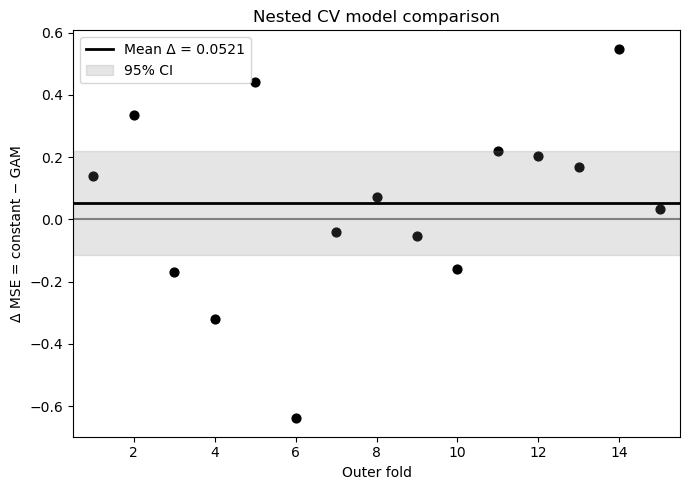

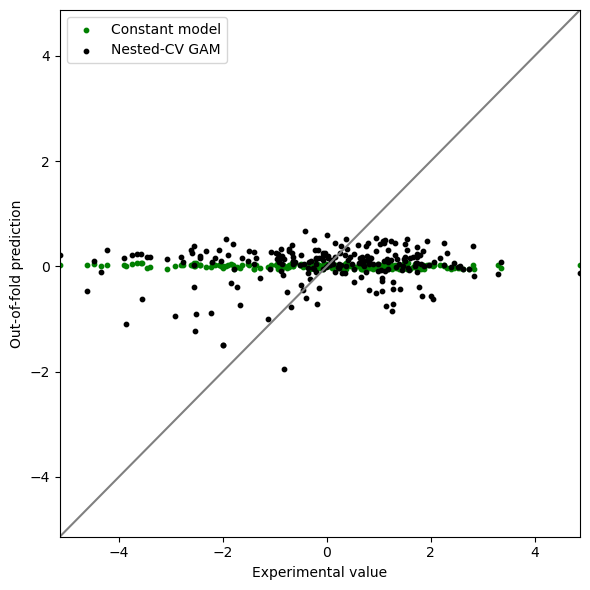

In [7]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

output_file = "../output/dataset_qy.pkl"

outer_delta_export = np.asarray(outer_delta, dtype=float)

with open(output_file, "wb") as f:
    pickle.dump(outer_delta_export, f)


fig, ax = plt.subplots(figsize=(7, 5))

ax.axhline(
    0,
    color="grey",
    linestyle="-",
)

ax.scatter(
    fold_number,
    outer_delta,
    s=40,
    color="black",
)

ax.axhline(
    mean_delta,
    color="black",
    linewidth=2,
    label=f"Mean Δ = {mean_delta:.3g}",
)

ax.fill_between(
    [0.5, n_outer_folds + 0.5],
    ci_low,
    ci_high,
    color="grey",
    alpha=0.2,
    label="95% CI",
)

ax.set_xlim(0.5, n_outer_folds + 0.5)
ax.set_xlabel("Outer fold")
ax.set_ylabel("Δ MSE = constant − GAM")
ax.set_title("Nested CV model comparison")
ax.legend()

fig.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    F,
    F_pred_constant_oof,
    s=10,
    color="green",
    label="Constant model",
    zorder=1,
)

ax.scatter(
    F,
    F_pred_gam_oof,
    s=10,
    color="black",
    label="Nested-CV GAM",
    zorder=2,
)

ax.plot(
    lims,
    lims,
    "-",
    color="grey",
)

ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_xlabel("Experimental value")
ax.set_ylabel("Out-of-fold prediction")
ax.legend()

fig.tight_layout()
plt.show()

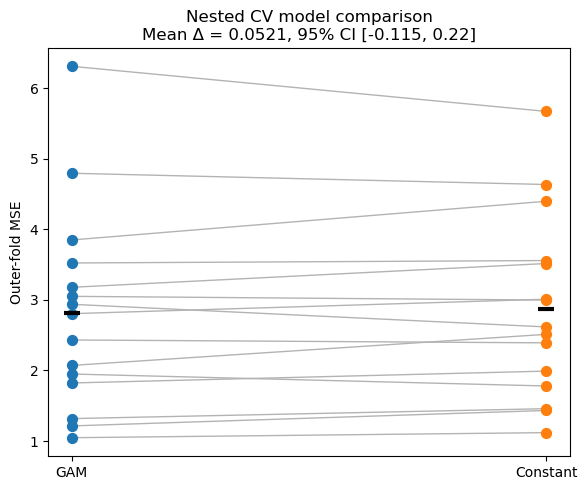

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))

x_gam = np.zeros(n_outer_folds)
x_constant = np.ones(n_outer_folds)

for i in range(n_outer_folds):
    ax.plot(
        [0, 1],
        [outer_gam_mse[i], outer_constant_mse[i]],
        color="0.7",
        linewidth=1,
        zorder=1,
    )

ax.scatter(
    x_gam,
    outer_gam_mse,
    s=50,
    label="GAM",
    zorder=2,
)

ax.scatter(
    x_constant,
    outer_constant_mse,
    s=50,
    label="Constant",
    zorder=2,
)

ax.scatter(
    [0, 1],
    [mean_gam_mse, mean_constant_mse],
    s=140,
    marker="_",
    linewidth=3,
    color="k",
    label="Mean",
    zorder=3,
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["GAM", "Constant"])
ax.set_ylabel("Outer-fold MSE")
ax.set_title(
    f"Nested CV model comparison\n"
    f"Mean Δ = {mean_delta:.3g}, 95% CI [{ci_low:.3g}, {ci_high:.3g}]"
)

#ax.legend()

fig.tight_layout()
plt.show()

In [9]:
t_stat, p_value = ttest_1samp(
    outer_delta,
    popmean=0.0,
    alternative="greater",
)

print("Mean Δ MSE:", np.mean(outer_delta))
print("t statistic:", t_stat)
print("one-sided p value:", p_value)

if p_value < 0.05:
    print("GAM has significantly lower MSE than the constant model.")
else:
    print("No significant evidence that the GAM has lower MSE than the constant model.")

Mean Δ MSE: 0.05212799792345078
t statistic: 0.6673352670411226
one-sided p value: 0.25770389119265985
No significant evidence that the GAM has lower MSE than the constant model.
